**Source package:** generated datasets and trained checkpoints are not included. Use the same `datasets/highway.npz` and the model exported by Lab 1. Follow the [build-from-source guide](../docs/FROM_SOURCE.md) before Run All. Saved outputs are cleared except the static teaching figures.

# Lab 2: Imagine and Plan with MPC

Use a trained world model to predict futures, select actions with MPC, and
inspect actual simulator outcomes. No training is needed in Lab 2.
Choose your world model below, run all cells and answer the three responses.

In [ ]:
# Locate the complete lab and import its bundled source package.
import os
import sys
from pathlib import Path

project_root = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "pyproject.toml").is_file()
     and (p / "src/lab1/__init__.py").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError(
        "Open the complete lab folder containing pyproject.toml and src/lab1. "
        "Follow START_HERE.md to launch Jupyter from that folder."
    )
os.chdir(project_root)
sys.path.insert(0, str(project_root / "src"))
print("working dir:", Path.cwd())
print("kernel Python:", sys.executable)

## Use Your Lab 1 World Model

This Source Package continues directly from Lab 1. Lab 2 finds the most recently exported checkpoint and uses it throughout prediction, imagination, MPC, animation and evaluation.


In [ ]:
# Source Package: use the model trained and exported in Lab 1
USE_MY_LAB1_MODEL = True

In [ ]:
#@title Apply the model choice (expand to inspect)
from pathlib import Path

if not isinstance(USE_MY_LAB1_MODEL, bool):
    raise ValueError("USE_MY_LAB1_MODEL must be True or False.")
SUPPLIED_MODEL_PATH = Path("checkpoints/reference/world_model_best.pt")
# Local Jupyter uses the most recently saved Lab 1 export; Colab asks for an upload.
saved_lab1_models = list(Path("outputs/my_build").glob("*/attempt_*/my_lab1_world_model.pt"))
PERSONAL_MODEL_PATH = (
    max(saved_lab1_models, key=lambda path: path.stat().st_mtime)
    if saved_lab1_models
    else None
)
ACTIVE_MODEL_PATH = PERSONAL_MODEL_PATH if USE_MY_LAB1_MODEL else SUPPLIED_MODEL_PATH
ACTIVE_MODEL_LABEL = "My Lab 1 model" if USE_MY_LAB1_MODEL else "Optional reference model"

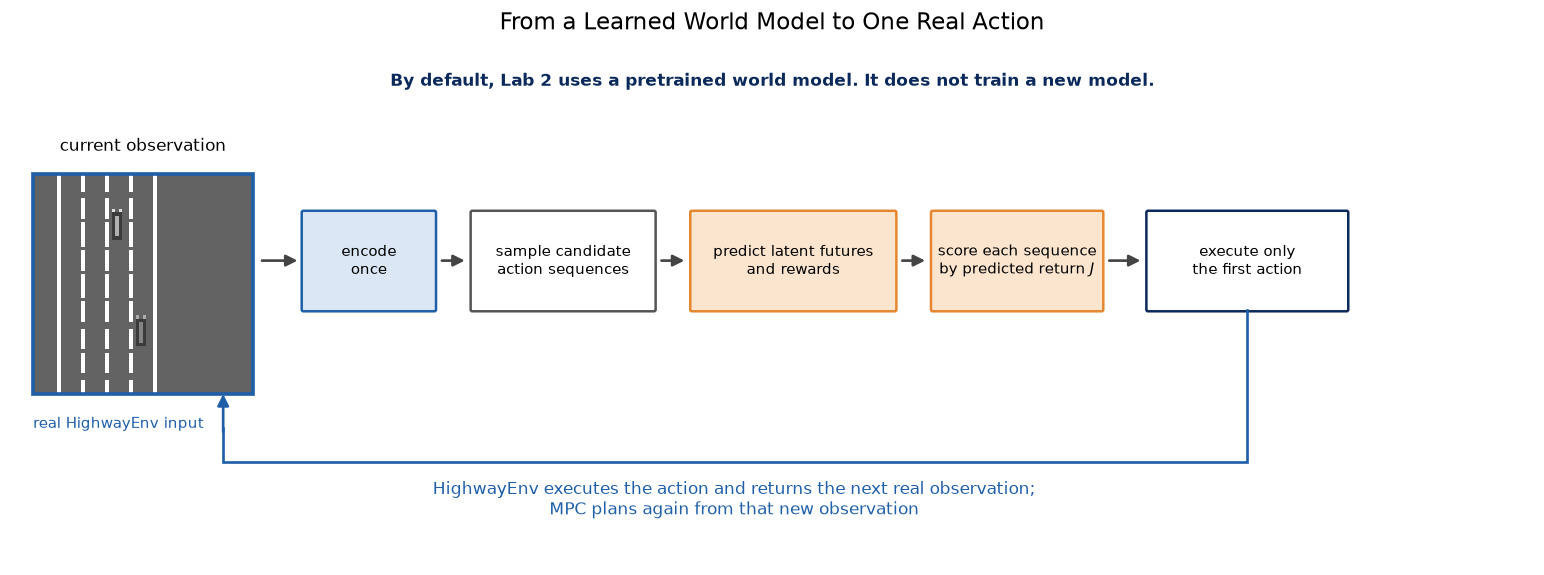

In [ ]:
from lab1.data import load_episodes
from notebooks.mpc_overview import plot_mpc_overview
from notebooks.upright_view import upright

overview_episode = load_episodes("datasets/highway.npz")[0]
overview = plot_mpc_overview(upright(overview_episode.obs[0, -1]), USE_MY_LAB1_MODEL)

## The world model

The car sees the road as a short stack of grayscale frames. The world model
compresses that view into a latent state and then answers one question:
*if I take this action now, what comes next, and how much reward will I get?*

In [ ]:
from lab1.visualization import plot_world_model_architecture

plot_world_model_architecture();

| Symbol | Meaning |
|---|---|
| $o_t$ | observation: a stack of recent frames |
| $a_t$ | action: lane left, idle, lane right, faster or slower |
| $r_{t+1}$ | reward the environment returns after $a_t$ |
| $z_t = E(o_t)$ | latent state produced by the encoder |
| $\hat z_{t+1} = f(z_t, a_t)$ | predicted next latent state |
| $\hat r_{t+1} = R(z_t, a_t)$ | predicted reward |

A hat marks a prediction. The next cell loads the trained model and a set of
held-out saved trajectories that the model never saw during training.

In [ ]:
import pickle

from lab1.config import Config
from lab1.data import load_num_actions, make_dataloaders
from lab1.models import WorldModel
from lab1.training import resolve_device
from lab1.utils import BUILD_OR_CORE, require_artifacts
from lab1.utils.checkpoint import load_checkpoint
from lab1.utils.model_handoff import load_personal_checkpoint
from notebooks.local_workflow import validate_student_preprocessing, StudentWorkflowError
from lab1.visualization import ACTION_NAMES

cfg = Config.load("configs/lab.yaml")
required = {cfg.data.dataset_path: "dataset configured in configs/lab.yaml"}
if not USE_MY_LAB1_MODEL:
    required[SUPPLIED_MODEL_PATH] = "optional reference checkpoint"
require_artifacts(required, remedy=BUILD_OR_CORE)
device = resolve_device(cfg.training.device)


def upload_lab1_model():
    import hashlib
    import os
    import tempfile

    from google.colab import files

    # Colab's upload API also writes files: isolate those writes from both models.
    previous_directory = Path.cwd()
    with tempfile.TemporaryDirectory(prefix="lab1-upload-") as temporary:
        try:
            os.chdir(temporary)
            uploaded = files.upload()
        finally:
            os.chdir(previous_directory)
    if not uploaded:
        raise ValueError(
            "No file uploaded. Rerun and upload the model saved by Lab 1."
        )
    if len(uploaded) != 1:
        raise ValueError(
            f"{len(uploaded)} files were uploaded. Rerun and upload only one Lab 1 model."
        )
    # Any filename is fine, e.g. "my_lab1_world_model (2).pt"; the contents are
    # validated below. The name is only displayed, never used as a path.
    ((uploaded_name, contents),) = uploaded.items()
    print(f"Uploaded checkpoint: {uploaded_name}")
    digest = hashlib.sha256(contents).hexdigest()
    destination = Path("outputs/personal_models") / digest / "my_lab1_world_model.pt"
    destination.parent.mkdir(parents=True, exist_ok=True)
    if not destination.exists():
        destination.write_bytes(contents)
    elif destination.read_bytes() != contents:
        raise ValueError(
            "An existing personal checkpoint differs; it was not overwritten."
        )
    return destination


if USE_MY_LAB1_MODEL:
    try:
        import google.colab
    except ImportError:
        if PERSONAL_MODEL_PATH is None or not PERSONAL_MODEL_PATH.is_file():
            raise StudentWorkflowError(
                "No saved Lab 1 model was found. Run Lab 1 through its final cell,\n"
                "then rerun Lab 2."
            ) from None
    else:
        PERSONAL_MODEL_PATH = upload_lab1_model()
    if PERSONAL_MODEL_PATH.resolve() == SUPPLIED_MODEL_PATH.resolve():
        raise ValueError(
            "The personal checkpoint must be separate from the supplied checkpoint."
        )
    ACTIVE_MODEL_PATH = PERSONAL_MODEL_PATH


def load_world_model(path):
    loaded_model = WorldModel.from_config(
        cfg.model, cfg.env, load_num_actions(cfg.data.dataset_path)
    ).to(device)
    if USE_MY_LAB1_MODEL:
        validate_student_preprocessing(path, cfg)
        handoff = load_personal_checkpoint(path, loaded_model, cfg)
        print(
            "Active world model: my Lab 1 model "
            f"({handoff['training_transitions']:,} transitions, "
            f"{handoff['epochs']} epochs, seed {handoff['seed']})"
        )
    else:
        load_checkpoint(path, loaded_model, map_location=device)
        print("Active world model: optional reference model")
    loaded_model.eval()
    loaded_model.requires_grad_(False)
    return loaded_model


print(f"Checkpoint: {ACTIVE_MODEL_PATH}")
try:
    model = load_world_model(ACTIVE_MODEL_PATH)
except (
    pickle.UnpicklingError, EOFError, OSError, TypeError, AttributeError, IndexError
):
    raise StudentWorkflowError(
        "This checkpoint is corrupt or is not a supported Lab 1 export.\n"
        "Download the model again from the final Lab 1 cell and upload that file."
    ) from None
except (ValueError, RuntimeError, KeyError) as error:
    raise StudentWorkflowError(
        f"Cannot load this model: {error}\n"
        "Use the Lab 1 model-only export with the unchanged teaching recipe."
    ) from None
_, _, _, val_eps = make_dataloaders(cfg)

N = cfg.planning.num_sequences  # candidate sequences per MPC decision (64)
H = cfg.planning.horizon  # MPC planning horizon (6)
print("held-out saved trajectories:", len(val_eps))


def identify_active_model(figure):
    figure.text(
        0.99,
        1.01,
        ACTIVE_MODEL_LABEL,
        ha="right",
        va="bottom",
        fontsize=9,
        color="#555555",
    )
    return figure

### Observed Effect of a Lane Change

These are **real saved observations**, not model predictions. The figure selects
a saved transition whose action requested **lane right**. It finds a lane-right transition in the generated dataset and prints
its trajectory and step. The road shifts relative to the camera-followed
ego vehicle; the car need not move across the image for the lane change to be visible.

This is one real simulator step (one second, 15 simulation substeps), not a
guarantee that lane-change requests succeed. It is separate from the held-out
one-step prediction target used in Question 1 below.


In [ ]:
from notebooks.recorded_lane_change import plot_recorded_lane_change

_ = plot_recorded_lane_change("datasets/highway.npz")


---
## Question 1: Can the world model predict a saved future?

Take one saved simulator trajectory from the held-out data. The model sees
only its first observation. We then hand it the **saved trajectory actions**,
one at a time, and ask what happens next.

> A **saved trajectory action** is the action that was taken in the saved
> simulator trajectory. It is not generated by the world model.

### 1.1 One step ahead

Encode $o_t$ into $z_t$, add the saved trajectory action $a_t$, and predict
$\hat z_{t+1}$ and $\hat r_{t+1}$. The saved trajectory tells us what actually
followed.

In [ ]:
import torch


def as_input(frames):
    return torch.from_numpy(frames.astype("float32") / 255.0).to(device)


ep = val_eps[0]  # one held-out saved trajectory, used throughout Question 1
o_t = as_input(ep.obs[0:1])
a_t = torch.from_numpy(ep.actions[0:1].astype("int64")).to(device)
with torch.no_grad():
    z_t = model.encode(o_t)  # z_t = E(o_t)
    z_next_pred = model.predict_next(z_t, a_t)  # predicted next latent
    r_next_pred = model.predict_reward(z_t, a_t)  # predicted reward
    z_next_ref = model.encode(as_input(ep.obs[1:2]))  # E(o_t+1), saved

one_step_error = ((z_next_pred - z_next_ref) ** 2).mean().item()
print(ACTIVE_MODEL_LABEL)
print("saved trajectory action a_t:", ACTION_NAMES[int(a_t[0])])
print(f"actual reward r_t+1:    {float(ep.rewards[0]):.3f}")
print(f"predicted reward:       {r_next_pred.item():.3f}")
print(f"one-step latent MSE:    {one_step_error:.5f}")

### 1.2 Imagining several steps ahead

Now feed each prediction back in. The model encodes only the first
observation, then rolls forward in latent space with the next saved trajectory
action:

```text
o_t ─encode once─▶ z_t ──a_t──▶ ẑ_t+1 ──a_t+1──▶ ẑ_t+2 ──▶ … ──▶ ẑ_t+H
```

$$\hat z_{t+1} = f(z_t, a_t), \qquad \hat z_{t+2} = f(\hat z_{t+1}, a_{t+1}),
\qquad \ldots$$

After the first step, every input is the model's own prediction, so small
errors can carry forward. How do we measure them?

### 1.3 What does latent prediction error compare?

In [ ]:
from lab1.visualization import plot_latent_error_paths

plot_latent_error_paths();

Future saved observations are used only as evaluation references. They are
not fed back into the imagined rollout. At each step $k$ we compare the two
latents, averaged over the $d$ latent dimensions:

$$\mathrm{MSE}_k = \frac{1}{d}\,\bigl\lVert \hat z_{t+k} - z^{\mathrm{ref}}_{t+k}
\bigr\rVert^2, \qquad z^{\mathrm{ref}}_{t+k} = E(o_{t+k})$$

The reference is the encoder's view of the saved observation, not the exact
physical state. First, the saved trajectory from 1.1 for $H = 6$ steps:

In [ ]:
from lab1.visualization import plot_latent_rollout
from notebooks.upright_view import upright_figure

_ = identify_active_model(
    upright_figure(plot_latent_rollout(model, ep, start=0, horizon=H, device=device))
)


One trajectory can be noisy. Repeating the rollout from 64 starting points in
held-out trajectories shows the average trend up to the planning horizon
$H = 6$ that MPC uses later:

In [ ]:
from lab1.imagination import prediction_error_vs_horizon
from lab1.visualization import plot_horizon_error

# Steps beyond H are kept for the optional diagnostic at the end.
stats = prediction_error_vs_horizon(
    model, val_eps, cfg.imagination.horizon, num_samples=64, device=device
)
_ = identify_active_model(
    plot_horizon_error(stats, planner_horizon=H, num_starts=64, max_horizon=H)
)
for k in (1, H):
    print(f"k = {k}: mean latent MSE {stats['mean'][k]:.5f}")


Inspect the one-step and six-step errors printed above for the active model.
Neither a single trajectory nor the mean has to rise at every step; recursive
predictions can carry forward earlier errors.

### 1.4 Reward prediction

The planner will rank actions by predicted reward, so we need to know what the
environment rewards. In this lab the reward is computed from four quantities of
the post-action simulator state:

| Symbol | Meaning | Values |
|---|---|---|
| $c_{t+1}$ | collision indicator | 0 or 1 |
| $\ell_{t+1}$ | target-lane score (0 = leftmost target, 1 = rightmost target) | $[0, 1]$ |
| $v_{t+1}$ | high-speed score (forward speed mapped from 20–30 m/s) | $[0, 1]$ |
| $m_{t+1}$ | on-road indicator | 0 or 1 |

The raw task score is

$$u_{t+1} = -1.0\,c_{t+1} + 0.1\,\ell_{t+1} + 0.4\,v_{t+1}.$$

HighwayEnv maps the raw range $[-1, 0.5]$ to $[0, 1]$ and gates it by whether
the vehicle remains on the road:

$$r_{t+1} = m_{t+1}\,\frac{u_{t+1} + 1}{1.5}.$$

For the controlled ego vehicle, HighwayEnv uses its **target lane**
for the right-lane term; this is not confirmation that a requested
lane change has physically completed.

A collision has weight $-1.0$. Right-lane driving contributes up to $0.1$ and
high speed up to $0.4$. Leaving the road makes the reward zero, and lane
changes earn no direct reward in this configuration. The normalized reward
lies in $[0, 1]$.

> This is the task reward used in the classroom environment. It is not a
> complete measure of driving safety.

The world model's reward head learns to predict $r_{t+1}$ from $z_t$ and
$a_t$. For the saved transition in 1.1, compare the received reward with the active
model's printed prediction. The received reward is the training target; the model predicts it.

During an imagined rollout, MPC repeatedly predicts rewards and adds them to
compute the candidate score $J$.

**Response 1.** Using the same saved action sequence, what two quantities are
compared, and why can their difference grow with horizon?

_Your answer._

---
## Question 2: How does MPC turn predicted futures into one real action?

In Question 1 the actions came from a saved trajectory, so a saved future
existed to check against. A planner must weigh action sequences that nobody
has tried, and for those the model's predictions are all we have. Model
predictive control (MPC) uses them to choose one action, executes it, and then
plans again.

In [ ]:
from lab1.visualization import plot_mpc_cycle

plot_mpc_cycle(num_candidates=N, horizon=H);

### 2.1 Scoring a candidate: the predicted return $J$

Each candidate is a sequence of $H$ actions. The model imagines it step by step
and adds up the predicted rewards:

$$J(a_{t:t+H-1}) = \sum_{k=0}^{H-1} \gamma^k\, \hat r_{t+k+1}$$

$J$ is the predicted return, or planning score, of one candidate action
sequence. $J$ is calculated inside the learned model. It is not the actual
episode return. This lab uses $H = 6$ and $\gamma = 1$, so $J$ is simply the
sum of six predicted rewards.

### 2.2 One decision

Random shooting proposes $N = 64$ candidates at random. The choice among them
is not random: MPC keeps the sequence with the highest $J$ and executes only
its first action. This cell runs one search from the first observation of the
saved trajectory. It does not step the environment.

In [ ]:
from lab1.planning import sample_candidate_plans
from lab1.visualization import plot_candidate_decision
from notebooks.upright_view import upright_figure

candidates = sample_candidate_plans(
    model,
    val_eps[0].obs[0],
    num_sequences=N,
    horizon=H,
    seed=cfg.seed,
    device=device,
)
best = candidates["best_index"]
best_sequence = [ACTION_NAMES[int(a)] for a in candidates["actions"][best]]
print(f"{N} candidates x {H} imagined steps = {N * H} imagined transitions")
print(f"highest predicted J = {candidates['returns'][best]:.3f}")
print("selected sequence:", " -> ".join([f"[{best_sequence[0]}]", *best_sequence[1:]]))
print(f"execute only the first action: {best_sequence[0]}")
_ = identify_active_model(
    upright_figure(plot_candidate_decision(val_eps[0].obs[0], candidates))
)


### 2.3 Execute, observe, replan

The next real observation can differ from what the model imagined. So MPC
executes one action, observes the new state, and searches again at every step.
Below are the first three decisions of one episode. The colored road is a
display view; the model sees only the grayscale input beside it.

In [ ]:
from lab1.planning import RandomShootingPlanner, rollout_with_policy
from lab1.visualization import plot_replanning_storyboard
from notebooks.upright_view import upright_figure, upright_run

DEMO_ENV_SEED = 1  # environment seed: the ego starts in a middle lane
PLANNER_SEED = 0  # seed for proposing random candidates


def run_mpc_episode(env_seed, num_sequences=N, horizon=H):
    planner = RandomShootingPlanner(
        model,
        num_sequences=num_sequences,
        horizon=horizon,
        device=device,
        seed=PLANNER_SEED,
    )
    decisions = []  # one (selected sequence, predicted J) per real decision

    def plan_then_act(model_observation):
        sequence, predicted_return = planner.plan(model_observation)
        decisions.append((sequence, predicted_return))
        return int(sequence[0])  # execute only the first action

    # record_display adds a color view for figures; the planner never sees it
    run = rollout_with_policy(
        cfg, plan_then_act, max_steps=30, seed=env_seed, record_display=True
    )
    return run, decisions


demo_run, demo_decisions = run_mpc_episode(DEMO_ENV_SEED)
print(f"start lane: {demo_run['lane_indices'][0]} of lanes 0-3 (0 = leftmost)")
print(
    "first five executed actions:",
    ", ".join(ACTION_NAMES[a] for a in demo_run["actions"][:5]),
)
_ = identify_active_model(
    upright_figure(plot_replanning_storyboard(demo_run, demo_decisions, count=3))
)


Each decision starts from a new observation and produces a new plan. A later
lane change, if selected, comes from a new search, not from carrying out the
remainder of an earlier plan.

**Response 2.** What is sampled, what is scored, what is selected, what is
actually executed, and why does MPC plan again?

_Your answer._

---
## Question 3: How well does the planner work in the simulator?

Predicted scores only matter if they lead to good driving. Let MPC drive and
look at what actually happens: first one full episode, then ten fixed seeds.

### 3.1 One full episode

The episode from 2.3, played to the end. The display camera follows the ego
vehicle and keeps it centered. Each frame shows the actual reward just
received and the next search.

In [ ]:
from lab1.visualization import animate_mpc_run

matches = all(
    int(sequence[0]) == action
    for (sequence, _), action in zip(demo_decisions, demo_run["actions"], strict=True)
)
print(
    f"executed action = first action of the selected sequence at every step: {matches}"
)
print(
    f"episode: {demo_run['steps']} real steps, actual return "
    f"{demo_run['total_reward']:.2f}, crashed = {demo_run['crashed']}"
)
animate_mpc_run(
    upright_run(demo_run),
    demo_decisions,
    title=f"{ACTIVE_MODEL_LABEL}: MPC Replans at Every Real Step, Environment Seed 1",
    note="Display view only: the camera follows the ego vehicle.",
)


### 3.2 Predicted return versus actual outcome

The same model and planner also drive environment seed 0, which starts in the
rightmost lane. Compare the first planning score with what actually happened.

In [ ]:
from lab1.visualization import plot_predicted_vs_actual

FAILURE_ENV_SEED = 0
failure_run, failure_decisions = run_mpc_episode(FAILURE_ENV_SEED)
for name, run, decisions in [
    ("seed 1", demo_run, demo_decisions),
    ("seed 0", failure_run, failure_decisions),
]:
    print(
        f"{name}: first predicted J {decisions[0][1]:.2f} | actual: {run['steps']} "
        f"real steps, return {run['total_reward']:.2f}, crashed = {run['crashed']}"
    )
_ = identify_active_model(
    plot_predicted_vs_actual(
        [
            ("Environment seed 1", demo_run, demo_decisions),
            ("Environment seed 0", failure_run, failure_decisions),
        ]
    )
)


Compare the active model's predicted scores with the observed outcomes above.
$J$ is a six-step prediction made inside the model at one moment. The episode return adds up actual rewards
over the whole drive. 

### 3.3 Ten fixed seeds

The planner and a random policy, which picks actions uniformly at random, each
drive the same ten environment seeds (0–9) for up to 30 steps. Here we add up
actual environment rewards.

In [ ]:
from lab1.planning import evaluate_planner_vs_random
from lab1.visualization import plot_ten_seed_evidence

EVAL_EPISODES = 10
comparison = evaluate_planner_vs_random(
    model,
    cfg,
    episodes=EVAL_EPISODES,
    max_steps=30,
    seed0=cfg.seed,
    device=device,
)
plan_r = comparison["planner_returns"]
rand_r = comparison["random_returns"]

print(f"Evaluation world model: {ACTIVE_MODEL_LABEL}")
EVAL_SEEDS = list(range(cfg.seed, cfg.seed + EVAL_EPISODES))
print(f"Fixed simulator seeds ({len(EVAL_SEEDS)}): {EVAL_SEEDS}")
print(f"planner actual episode return: {plan_r.mean():.2f} +/- {plan_r.std():.2f}")
print(f"random  actual episode return: {rand_r.mean():.2f} +/- {rand_r.std():.2f}")
print("+/- is the episode standard deviation, not a confidence interval.")
print(
    f"crashes: planner={comparison['planner_crashes']}/{EVAL_EPISODES}, "
    f"random={comparison['random_crashes']}/{EVAL_EPISODES}"
)

from IPython.display import Markdown, display

display(
    Markdown(
        f"**{ACTIVE_MODEL_LABEL} — actual simulator outcomes**\n\n"
        "| Policy | Mean episode return ± episode SD | Crashes | Episodes | Fixed seeds |\n"
        "|---|---:|---:|---:|---|\n"
        f"| MPC | {plan_r.mean():.2f} ± {plan_r.std():.2f} | "
        f"{comparison['planner_crashes']}/{EVAL_EPISODES} | {EVAL_EPISODES} | {EVAL_SEEDS} |\n"
        f"| Random | {rand_r.mean():.2f} ± {rand_r.std():.2f} | "
        f"{comparison['random_crashes']}/{EVAL_EPISODES} | {EVAL_EPISODES} | {EVAL_SEEDS} |"
    )
)
_ = identify_active_model(plot_ten_seed_evidence(comparison))


The table reports actual simulator rewards, not predicted $J$. Compare the
planner's observed returns, episode variation and crashes with the random
policy; a higher observed mean alone is not proof that the planner is better.

> Ten fixed episodes are useful for inspection, but do not establish statistical superiority, robustness or safety.

**Why the planner can still crash.**

- $J$ looks only six steps ahead.
- The model does not predict when an episode ends, so a sequence that would
  crash keeps collecting predicted reward.
- Latent and reward errors from Question 1 can mislead the choice.

This experiment cannot tell which of these caused any particular crash.

**Response 3.** What conclusion does the ten-seed result support, what does it
not establish, and why is a high predicted return $J$ not proof of a safe or
high-return episode?

_Your answer._

---
## Summary

In [ ]:
from lab1.visualization import plot_lab_synthesis

plot_lab_synthesis();

**The required lab ends here.**

In [ ]:
print(f"Lab 2 complete — {ACTIVE_MODEL_LABEL}.")
print("Imagination, MPC driving and the 10-seed evaluation finished.")
print("Answer Responses 1–3. Optional exercises below do not run automatically.")


---
# Optional exploration

Run all only defines these exercises; it does not execute another episode or
animation. After the required activity, edit the settings and run a new code
cell containing the function call shown under an exercise. Change one factor
at a time.

In [ ]:
N_CANDIDATES = 64   # candidates per decision; try 8 or 256
HORIZON = 6         # imagined steps per candidate; try 2 or 10
CANDIDATE_SEED = 0  # seed for proposing candidates; try 1 or 2
EPISODE_SEED = 0    # environment seed for the full episode in B; try 2 or 5

### A. One planning decision

Does a longer horizon or a larger search change the chosen action? Raw $J$
sums $H$ rewards, so compare horizons with $J/H$.

Run `explore_planning_decision()` in a new code cell.

In [ ]:
def explore_planning_decision():
    from lab1.planning import probe_planning_decision
    from lab1.visualization import planner_probe_table


    def probe(n, h, seed):  # one planning decision; no environment step
        return probe_planning_decision(
            model, val_eps[0].obs[0], num_sequences=n, horizon=h, seed=seed, device=device
        )


    settings = [(N, H, cfg.seed), (N_CANDIDATES, HORIZON, CANDIDATE_SEED)]
    print(ACTIVE_MODEL_LABEL)
    print(planner_probe_table([probe(*s) for s in dict.fromkeys(settings)], show_sequence=True))


### B. A full episode with your settings

With unchanged settings this replays the seed-0 episode from 3.2.

Run `explore_mpc_episode()` in a new code cell to generate this extra animation.

In [ ]:
def explore_mpc_episode():
    explore_run, explore_decisions = run_mpc_episode(EPISODE_SEED, N_CANDIDATES, HORIZON)
    print(
        f"start lane {explore_run['lane_indices'][0]}; {explore_run['steps']} real steps, "
        f"return {explore_run['total_reward']:.2f}, crashed = {explore_run['crashed']}"
    )
    return animate_mpc_run(
        upright_run(explore_run),
        explore_decisions,
        title=f"{ACTIVE_MODEL_LABEL}: MPC Episode, Environment Seed {EPISODE_SEED}, N = {N_CANDIDATES}, H = {HORIZON}",
    )


### C. Latent error beyond the MPC horizon

The plot in 1.3 stopped at $H = 6$. Horizons 7–10 are a diagnostic beyond the
MPC horizon. Run `explore_longer_horizon()` in a new code cell.

In [ ]:
def explore_longer_horizon():
    _ = identify_active_model(plot_horizon_error(stats, planner_horizon=H, num_starts=64))
    for k in (1, H, len(stats["mean"]) - 1):
        print(f"k = {k:>2}: mean latent MSE {stats['mean'][k]:.5f}")


### D. Per-step reward predictions

Compare the actual reward, the prediction from each observed state, and the
prediction from the recursively imagined state across the saved trajectory.

Run `explore_reward_predictions()` in a new code cell.

In [ ]:
def explore_reward_predictions():
    from lab1.visualization import plot_cumulative_reward_prediction, plot_reward_prediction

    _ = identify_active_model(plot_reward_prediction(model, ep, device=device))
    _ = identify_active_model(plot_cumulative_reward_prediction(model, ep, device=device))
